<a href="https://colab.research.google.com/github/Rakko-Yumiya/Computer-Vision-Project-Overview-Cyclist/blob/main/ComputerVisionProject_multiServerSelection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1> <b> Object Detection Using YOLO <b> </h1></center>

## Setup: environment and paths

Run this cell first. It detects whether you are on **Google Colab**, **Windows** or **Mac**, picks the base folder (Google Drive or a local folder) and defines every path used below. To change where things live, edit `STORAGE` / `BASE_DIR_OVERRIDE` at the top of the cell.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# =============================================================================
# SETUP: detect the environment and define EVERY path once. Run this cell first.
# Everything below uses these variables; no other cell defines a path.
# =============================================================================
import os, sys, glob, string, platform

# ---- 1. Your choices (the only part you ever need to edit) ------------------
STORAGE = 'auto'          # 'auto'  -> Google Drive if available, else a local folder
                          # 'drive' -> insist on Google Drive (Colab mount, or Drive for desktop)
                          # 'temp' -> temp disk (Colab: /content, fast but lost when the session ends)
BASE_DIR_OVERRIDE = 'G:/Study/Colab_Notebooks'  # or your own folder, e.g. r'D:\ML\Colab_Notebooks'  or  '/Users/me/Colab_Notebooks'
FOLDER = 'Colab_Notebooks'

# ---- 2. Detect where we are running -----------------------------------------
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

OS_NAME = {'Windows': 'Windows', 'Darwin': 'Mac'}.get(platform.system(), 'Linux')
home = os.path.expanduser('~')


def find_local_drive():
    """Google Drive for desktop ('My Drive') on this computer, or None."""
    if OS_NAME == 'Windows':
        candidates = [f'{letter}:/My Drive' for letter in string.ascii_uppercase[2:]]  # C: .. Z:
    elif OS_NAME == 'Mac':
        candidates = glob.glob(os.path.join(home, 'Library/CloudStorage/GoogleDrive-*/My Drive'))
        candidates += [os.path.join(home, 'Google Drive/My Drive'), os.path.join(home, 'Google Drive')]
    else:
        candidates = [os.path.join(home, 'Google Drive')]
    return next((c for c in candidates if os.path.isdir(c)), None)


# ---- 3. Pick the base folder --------------------------------------------------
if BASE_DIR_OVERRIDE:
    root = BASE_DIR_OVERRIDE
elif IN_COLAB:
    root = os.path.join('/content/drive/MyDrive' if STORAGE in ('auto', 'drive') else '/content', FOLDER)
else:
    drive_root = find_local_drive()
    if STORAGE == 'drive' and drive_root is None:
        raise FileNotFoundError("STORAGE='drive' but Google Drive for desktop was not found. "
                                "Install it, or set BASE_DIR_OVERRIDE to a folder.")
    use_drive = STORAGE in ('auto', 'drive') and drive_root is not None
    root = os.path.join(drive_root if use_drive else home, FOLDER)

base_dir = os.path.abspath(os.path.expanduser(root))

if IN_COLAB and base_dir.startswith('/content/drive'):
    from google.colab import drive
    drive.mount('/content/drive')

# ---- 4. Every path the notebook uses ------------------------------------------
dataset_url = ('https://github.com/zhengyangsu/Computer-Vision-Project-Overview/'
               'releases/download/v1.0/Cycling_Hand_Signals_Dataset.zip')

splits = ['train', 'valid', 'test']

# original dataset (images and labels together in each split)
data_dir = os.path.join(base_dir, 'Cycling_Hand_Signals_Dataset')
split_dirs = {s: os.path.join(data_dir, s) for s in splits}
src_images = {s: os.path.join(split_dirs[s], 'images') for s in splits}
src_labels = {s: os.path.join(split_dirs[s], 'labels') for s in splits}

# YOLO layout: Final_data/images/<split> and Final_data/labels/<split>
final_dir = os.path.join(data_dir, 'Final_data')
image_dir = os.path.join(final_dir, 'images')
label_dir = os.path.join(final_dir, 'labels')
final_images = {s: os.path.join(image_dir, s) for s in splits}
final_labels = {s: os.path.join(label_dir, s) for s in splits}

# training outputs
config_path = os.path.join(base_dir, 'config.yaml')
project_dir = os.path.join(base_dir, 'workbench')

# ---- 5. Create the folders ----------------------------------------------------
for folder in [base_dir, project_dir, *final_images.values(), *final_labels.values()]:
    os.makedirs(folder, exist_ok=True)

print(f'Environment : {"Colab" if IN_COLAB else "Local"} / {OS_NAME}')
print(f'base_dir    : {base_dir}')
print(f'data_dir    : {data_dir}')
print(f'final_dir   : {final_dir}')
print(f'project_dir : {project_dir}')
print(f'config_path : {config_path}')
os.chdir(base_dir)


Environment : Local / Windows
base_dir    : G:\Study\Colab_Notebooks
data_dir    : G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset
final_dir   : G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data
project_dir : G:\Study\Colab_Notebooks\workbench
config_path : G:\Study\Colab_Notebooks\config.yaml


Importing required Libraries

In [7]:
from PIL import Image
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import glob
import xml.etree.ElementTree as ET
import shutil

# Dataset Description






# Data  

### Classification:  
0: Caution  
1: Cyclist  
2: Left Turn  
3: Right Turn  
4: Stop

In [8]:
import tempfile
import urllib.request
import zipfile

def download_dataset(url, dest):
    """Download the zip and unpack it into dest (works on Colab, Windows and Mac)."""
    if os.path.isdir(os.path.join(dest, 'Cycling_Hand_Signals_Dataset')):
        print(f'Dataset already exists at {dest}, skipping download.')
        return
    os.makedirs(dest, exist_ok=True)
    with tempfile.TemporaryDirectory() as tmp:
        zip_path = os.path.join(tmp, 'dataset.zip')
        print('Downloading dataset ...')
        urllib.request.urlretrieve(url, zip_path)
        print('Unzipping ...')
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(dest)
    print('Done.')


download_dataset(dataset_url, base_dir)
print(os.listdir(data_dir))

Dataset already exists at G:\Study\Colab_Notebooks, skipping download.
['data.yaml', 'Final_data', 'README.roboflow.txt', 'test', 'train', 'valid']


# Data Preprocessing

For preprocessing:
- We have to convert the dataset into that acceptable by YOLO.
  - Heirarchy of folders should be the one accepted by YOLO
  - Labels format should be darknet YOLO.
  - Labels files should be .txt files
- Check and see if there are any missing labels or images. And remove them from dataset.


## Heirarchy of Folders correction



The train and test folders have all the images and labels together.

But for YOLO, the directories should be in:

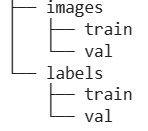


The YOLO folder structure (`Final_data/images/<split>` and `Final_data/labels/<split>`) is created in the setup cell at the top.

Copy TXT files and jpg files from the train folder to the folders created.

In [ ]:
# Names of the subfolders inside each original split.
# The paths themselves (src_images, src_labels, final_images, final_labels) come from the setup cell.


def copy_files(src_folder, dst_folder, extensions):
    """Copy files with the given extensions from src_folder to dst_folder."""
    if os.path.isdir(dst_folder) and os.listdir(dst_folder):
        print(f'  skipped {dst_folder} (already has {len(os.listdir(dst_folder))} files)')
        return 0

    os.makedirs(dst_folder, exist_ok=True)
    count = 0
    for file in os.listdir(src_folder):
        if os.path.splitext(file)[1].lower() in extensions:
            shutil.copy(os.path.join(src_folder, file), dst_folder)
            count += 1
    return count


for split in splits:
    n_img = copy_files(src_images[split], final_images[split], ('.jpg', '.jpeg', '.png'))
    n_lbl = copy_files(src_labels[split], final_labels[split], ('.txt',))
    print(f'{split}: copied {n_img} images, {n_lbl} labels')

  skipped G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\images\train (already has 6141 files)
  skipped G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\labels\train (already has 6141 files)
train: copied 0 images, 0 labels
  skipped G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\images\valid (already has 1535 files)
  skipped G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\labels\valid (already has 1535 files)
valid: copied 0 images, 0 labels
  skipped G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\images\test (already has 156 files)
  skipped G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\labels\test (already has 156 files)
test: copied 0 images, 0 labels


Visualizing somme pictures from the dataset

G:\Study\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\images\train


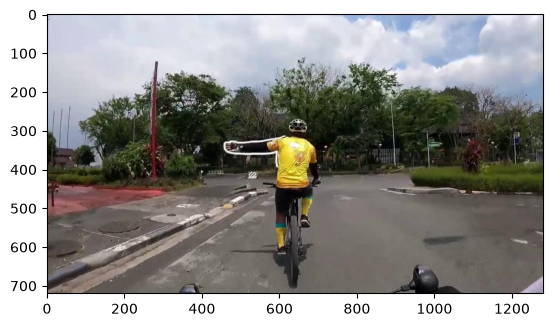

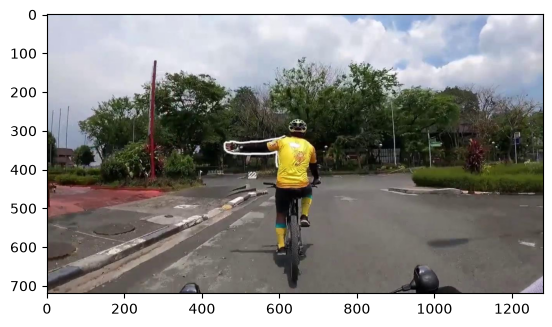

In [ ]:
#visualize first four sample images from train data
print(os.path.join(final_images['train']))


for idx, image in enumerate(os.listdir(final_images['train'])):
    img = cv2.imread(os.path.join(final_images['train'], image), 1)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) #color conversion
    plt.imshow(img)
    plt.show()

    if idx == 1:
        break


## Creating Dataframe from txt labels
Creating Dataframes from txt files


In [ ]:
class_names = ['Caution', 'Cyclist', 'Left Turn', 'Right Turn', 'Stop']

rows = []
for split in splits:
    label_folder = src_labels[split]
    for file in os.listdir(label_folder):
        if not file.endswith('.txt'):
            continue
        with open(os.path.join(label_folder, file)) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:          # skip blank or malformed lines
                    continue
                rows.append({
                    'split': split,
                    'name': os.path.splitext(file)[0],
                    'class': int(parts[0]),
                    'x_center': float(parts[1]),
                    'y_center': float(parts[2]),
                    'box_width': float(parts[3]),
                    'box_height': float(parts[4]),
                })

df = pd.DataFrame(rows)
df['label'] = df['class'].map(dict(enumerate(class_names)))
#display(df.head())
cols = ['split', 'class', 'label', 'x_center', 'y_center', 'box_width', 'box_height', 'name'] #reorder columns
df = df[cols]
display(df.sample(10, random_state=0))
print(df['split'].value_counts())

,split,class,label,x_center,y_center,box_width,box_height,name
5571,train,0,Caution,0.308594,0.719903,0.082469,0.208333,3rd-edited-mp4_frame3706_jpg.rf.9a093281fe042d...
3132,train,0,Caution,0.479297,0.416667,0.078906,0.077778,2nd-Edited-mp4_frame5768_jpg.rf.c2a143a1b5f1e3...
7029,train,1,Cyclist,0.723828,0.541667,0.110156,0.713889,4th-vid-mp4_frame1371_jpg.rf.f9efce9728803e88d...
634,train,1,Cyclist,0.510539,0.606125,0.123672,0.562278,1st-edited-mp4_frame78_jpg.rf.5be7f66f2b66eb8e...
8768,train,2,Left Turn,0.825781,0.279861,0.131250,0.412500,4th-vid-mp4_frame866_jpg.rf.7ce16244a44e9a4aca...
10266,valid,0,Caution,0.307422,0.525000,0.208594,0.438889,3rd-edited-mp4_frame2693_jpg.rf.6e462dfb6af860...
7345,train,2,Left Turn,0.534375,0.425000,0.076563,0.036111,4th-vid-mp4_frame247_jpg.rf.6f55a016f4ace06d30...
9375,valid,1,Cyclist,0.389062,0.600694,0.176563,0.798611,2nd-Edited-mp4_frame3064_jpg.rf.2642d8492a0abc...
4519,train,3,Right Turn,0.705859,0.327778,0.308594,0.280556,3rd-edited-mp4_frame1120_jpg.rf.a748edff9101e4...
7389,train,2,Left Turn,0.535156,0.407403,0.070312,0.074069,4th-vid-mp4_frame260_jpg.rf.7cf986f7da73a651b8...


split
train    8949
valid    2256
test      338
Name: count, dtype: int64


Sanity Check

In [ ]:
# Class balance per split
print(df.groupby(['split', 'label']).size().unstack(fill_value=0), end="\n\n")

# Images with no boxes
n_labeled = df.groupby('split')['name'].nunique()
print(n_labeled, end="\n\n")

# Sanity check: bb between 0 and 1
print(df[['x_center', 'y_center', 'box_width', 'box_height']].describe())

label  Caution  Cyclist  Left Turn  Right Turn  Stop
split                                               
test        41      174         45          48    30
train     1922     4375        763         899   990
valid      447     1110        198         256   245

split
test      155
train    4939
valid    1260
Name: name, dtype: int64

           x_center      y_center     box_width    box_height
count  11543.000000  11543.000000  11543.000000  11543.000000
mean       0.484959      0.515232      0.170050      0.487362
std        0.170216      0.116652      0.095527      0.302677
min        0.051562      0.014319      0.000813      0.000000
25%        0.343750      0.444444      0.100781      0.212500
50%        0.460938      0.532403      0.151562      0.432375
75%        0.636371      0.593881      0.212949      0.775000
max        0.953125      1.000000      0.840517      1.000000


In [ ]:
#train_df = df[df['split'] == 'train'].reset_index(drop=True)
train_df = df[df['split'] == 'train']
val_df = df[df['split'] == 'valid']
test_df = df[df['split'] == 'test']

print('Train')
display(train_df.head(5))
print('\n\nVal')
display(val_df.head(5))
print('\n\nTest')
display(test_df.sample(5))



Train


,split,class,label,x_center,y_center,box_width,box_height,name
0,train,1,Cyclist,0.500437,0.667444,0.106773,0.618833,1st-edited-mp4_frame100_jpg.rf.728c868127d52c4...
1,train,2,Left Turn,0.418406,0.468361,0.135414,0.091056,1st-edited-mp4_frame100_jpg.rf.728c868127d52c4...
2,train,1,Cyclist,0.504687,0.665972,0.104688,0.587500,1st-edited-mp4_frame101_jpg.rf.778baaff37bd44d...
3,train,2,Left Turn,0.413672,0.475000,0.114844,0.066667,1st-edited-mp4_frame101_jpg.rf.778baaff37bd44d...
4,train,1,Cyclist,0.509375,0.624306,0.098437,0.706944,1st-edited-mp4_frame103_jpg.rf.82ceef5110479c0...




Val


,split,class,label,x_center,y_center,box_width,box_height,name
8949,valid,2,Left Turn,0.415234,0.470833,0.122656,0.088889,1st-edited-mp4_frame102_jpg.rf.9ed6c2d2e6307c1...
8950,valid,1,Cyclist,0.504687,0.663889,0.107813,0.600000,1st-edited-mp4_frame102_jpg.rf.9ed6c2d2e6307c1...
8951,valid,2,Left Turn,0.412891,0.468750,0.130469,0.095833,1st-edited-mp4_frame105_jpg.rf.93490f156fe66e3...
8952,valid,1,Cyclist,0.505078,0.661806,0.100781,0.590278,1st-edited-mp4_frame105_jpg.rf.93490f156fe66e3...
8953,valid,2,Left Turn,0.413281,0.468750,0.123438,0.081944,1st-edited-mp4_frame106_jpg.rf.381b9e1f3f7c759...




Test


,split,class,label,x_center,y_center,box_width,box_height,name
11379,test,2,Left Turn,0.666379,0.332694,0.346552,0.349057,cyclistHandSignal_test_0024
11369,test,3,Right Turn,0.703291,0.250538,0.403708,0.369892,cyclistHandSignal_test_0020
11424,test,1,Cyclist,0.561782,0.550218,0.217370,0.640466,IMG_6842
11432,test,1,Cyclist,0.522966,0.613537,0.240660,0.653566,IMG_6846
11356,test,3,Right Turn,0.469892,0.218280,0.292473,0.146237,cyclistHandSignal_test_0014


Visualizing one of the image in train set with the bounding box

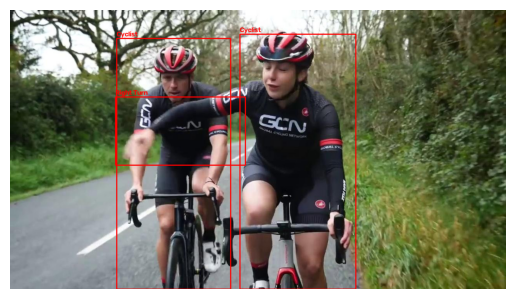

In [ ]:
index = 2424
name = train_df.loc[index, 'name']

img = cv2.imread(os.path.join(src_images['train'], f'{name}.jpg'))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)            # fix the blue-tint color order
h, w = img.shape[:2]

# All box for this image (an image can have several rows, cyclist plus hand signal)
for _, row in train_df[train_df['name'] == name].iterrows():
    x1 = int((row['x_center'] - row['box_width']  / 2) * w) #multiple as yolo label store coordinate as fraction
    y1 = int((row['y_center'] - row['box_height'] / 2) * h)
    x2 = int((row['x_center'] + row['box_width']  / 2) * w)
    y2 = int((row['y_center'] + row['box_height'] / 2) * h)

    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
    cv2.putText(img, str(row['label']), (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.imshow(img)
plt.axis('off')
plt.show()

#display(train_df.loc[10:18, ['name', 'label', 'x_center', 'y_center', 'box_width', 'box_height']])
#print(train_df.loc[10:18, 'name'].nunique(), "different image name(s)")

Checking to see if the above image has bounding boxes around other cylist/hand gesture or not.

In [ ]:
train_df["name"][index]
filtered_df = train_df[train_df['name'] == train_df["name"][index]]
print(filtered_df)

      split  class       label  x_center  y_center  box_width  box_height  \
2424  train      3  Right Turn  0.343359  0.433333   0.261719    0.244444   
2425  train      1     Cyclist  0.329688  0.550694   0.229687    0.898611   
2426  train      1     Cyclist  0.580078  0.543750   0.233594    0.912500   

                                                   name  
2424  2nd-Edited-mp4_frame521_jpg.rf.ff339724ed70e47...  
2425  2nd-Edited-mp4_frame521_jpg.rf.ff339724ed70e47...  
2426  2nd-Edited-mp4_frame521_jpg.rf.ff339724ed70e47...  


Checking to see the datatypes of all the columns and if there is any null value that needs to be eliminated from the data.

In [ ]:
print('train')
train_df.info()
print('val\n\n')
val_df.info()
print('test\n\n')
test_df.info()

train
<class 'pandas.DataFrame'>
RangeIndex: 8949 entries, 0 to 8948
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   split       8949 non-null   str    
 1   class       8949 non-null   int64  
 2   label       8949 non-null   str    
 3   x_center    8949 non-null   float64
 4   y_center    8949 non-null   float64
 5   box_width   8949 non-null   float64
 6   box_height  8949 non-null   float64
 7   name        8949 non-null   str    
dtypes: float64(4), int64(1), str(3)
memory usage: 559.4 KB
val


<class 'pandas.DataFrame'>
RangeIndex: 2256 entries, 8949 to 11204
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   split       2256 non-null   str    
 1   class       2256 non-null   int64  
 2   label       2256 non-null   str    
 3   x_center    2256 non-null   float64
 4   y_center    2256 non-null   float64
 5   box_width   2256 non-null   floa

What different types of labels are assigned to each sample and checking if they match the provided label/class information, i.e. there are no extra labels due to mistakes in spellings etc.

In [ ]:
print(train_df['split'].unique())
print(val_df['split'].unique())
print(test_df['split'].unique())

print(train_df['label'].unique())
print(val_df['label'].unique())
print(test_df['label'].unique())

<StringArray>
['train']
Length: 1, dtype: str
<StringArray>
['valid']
Length: 1, dtype: str
<StringArray>
['test']
Length: 1, dtype: str
<StringArray>
['Cyclist', 'Left Turn', 'Caution', 'Stop', 'Right Turn']
Length: 5, dtype: str
<StringArray>
['Left Turn', 'Cyclist', 'Caution', 'Stop', 'Right Turn']
Length: 5, dtype: str
<StringArray>
['Cyclist', 'Right Turn', 'Left Turn', 'Caution', 'Stop']
Length: 5, dtype: str


Deleting all the sample with Nan values in training and validation data

In [ ]:
#training
print("before deleting (train data): " , train_df.shape)

train_df = train_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(train_data): " ,train_df.shape)

#validation
print("before deleting (val data): " , val_df.shape)
val_df   = val_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(val data): " , val_df.shape)

#test
print("before deleting (test data): " , test_df.shape)
test_df   = test_df.replace([np.inf, -np.inf], np.nan).dropna()
print("after deleting(val data): " , test_df.shape)

before deleting (train data):  (8949, 8)
after deleting(train_data):  (8949, 8)
before deleting (val data):  (2256, 8)
after deleting(val data):  (2256, 8)
before deleting (test data):  (340, 8)
after deleting(val data):  (340, 8)


converting the dataframe to type *str* (string) to be stored in text files.

In [ ]:
train_df = train_df.astype(str)
val_df = val_df.astype(str)
test_df = test_df.astype(str)

If there are more than one bounding boxes in single image, they should be written in one text file. As, you can see in the below example that one image has so many bounding boxes.

In [ ]:
filtered_df = train_df[train_df['name'] == train_df["name"][2424]]
(filtered_df.head(10))

,split,class,label,x_center,y_center,box_width,box_height,name
2424,train,3,Right Turn,0.343359375,0.43333333333333335,0.26171875,0.24444444444444444,2nd-Edited-mp4_frame521_jpg.rf.ff339724ed70e47...
2425,train,1,Cyclist,0.3296875,0.5506944444444445,0.2296875,0.8986111111111111,2nd-Edited-mp4_frame521_jpg.rf.ff339724ed70e47...
2426,train,1,Cyclist,0.580078125,0.54375,0.23359375,0.9125,2nd-Edited-mp4_frame521_jpg.rf.ff339724ed70e47...


In [ ]:
#only need it if we have multiple txt per image
def write_labels(d, out_dir):
    """Write one YOLO label file per image: 'class x_center y_center width height' per box."""
    os.makedirs(out_dir, exist_ok=True)
    for name, boxes in d.groupby('name'):
        lines = [
            f"{int(r['class'])} {r['x_center']:.6f} {r['y_center']:.8f} "
            f"{r['box_width']:.6f} {r['box_height']:.6f}"
            for _, r in boxes.iterrows()
        ]
        with open(os.path.join(out_dir, f'{name}.txt'), 'w') as f:
            f.write("\n".join(lines))

tables = {'train': train_df, 'valid': val_df, 'test': test_df}

for split, d in tables.items():
    write_labels(d, os.path.join(label_dir, split))
    print(f"{split}: wrote {d['name'].nunique()} label files")

ValueError: Unknown format code 'f' for object of type 'str'

## Checking Missing Files

Checking the folders if every image file has a corresponding label file


(We will copy the code, we already used in previous turorial after updating)

In [ ]:
def stems(folder, pattern):
    return {os.path.splitext(os.path.basename(f))[0]
            for f in glob.glob(os.path.join(folder, pattern))}

check = {}   # all results live here

for split in splits:
    images = stems(src_images[split], '*.jpg')
    labels = stems(src_labels[split], '*.txt')

    check[split] = {
        'images': images,
        'labels': labels,
        'images_no_label': images - labels,
        'labels_no_image': labels - images,
    }

    print(f"{split}: {len(images)} images, {len(labels)} labels, " #image and label counts per split, not instances
          f"{len(check[split]['images_no_label'])} images without label, "
          f"{len(check[split]['labels_no_image'])} labels without image")

train: 6141 images, 6141 labels, 0 images without label, 0 labels without image
valid: 1535 images, 1535 labels, 0 images without label, 0 labels without image
test: 155 images, 155 labels, 0 images without label, 0 labels without image


In [ ]:
def stems(folder, pattern):
    """File names without folder or extension, as a set."""
    return {os.path.splitext(os.path.basename(f))[0]
            for f in glob.glob(os.path.join(folder, pattern))}

def check_split(split):
    images = stems(src_images[split], '*.jpg')
    labels = stems(src_labels[split], '*.txt')
    return {
        'images': images,
        'labels': labels,
        'images_no_label': images - labels,
        'labels_no_image': labels - images,
    }

train = check_split('train')
valid = check_split('valid')
test  = check_split('test')

for name, r in [('train', train), ('valid', valid), ('test', test)]:
    print(f"{name}: {len(r['images'])} images, {len(r['labels'])} labels, "
          f"{len(r['images_no_label'])} images without label, "
          f"{len(r['labels_no_image'])} labels without image")

train: 6141 images, 6141 labels, 0 images without label, 0 labels without image
valid: 1535 images, 1535 labels, 0 images without label, 0 labels without image
test: 155 images, 155 labels, 0 images without label, 0 labels without image


Make sure that the above info is correct by chceking the data manually.

Now removing from the dataset:

In [ ]:
for split, r in [('train', train), ('valid', valid), ('test', test)]:
    for file in r['images_no_label']:
        os.remove(os.path.join(src_images[split], file + '.jpg'))

for split, r in [('train', train), ('valid', valid), ('test', test)]:
    for file in r['labels_no_image']:
        os.remove(os.path.join(src_labels[split], file + '.txt'))

Now run the above cells again to find if all the missing data is deleted.

# Custom object detection using YOLO

First install and import

In [9]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.198  Python-3.13.15 torch-2.15.0+cpu CPU (Intel Core i5-9300H 2.40GHz)
Setup complete  (8 CPUs, 31.8 GB RAM, 176.7/306.5 GB disk)


In [10]:
from ultralytics import YOLO

## Training YOLO

We are going to select small pretrained (on COCO dataset) model of YOLOv8

In [11]:
model = YOLO('yolov8s.pt') # pretrained model

print('Working directory :', os.getcwd())
print('Weights file      :', os.path.abspath('yolov8s.pt'))
print('Exists            :', os.path.exists('yolov8s.pt'))
print('Loaded from       :', model.ckpt_path)

Working directory : G:\Study\Colab_Notebooks
Weights file      : G:\Study\Colab_Notebooks\yolov8s.pt
Exists            : True
Loaded from       : yolov8s.pt


The detailed architecture of the model can be seen from:


In [12]:
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0

In [13]:
config = f"""path: "{final_dir.replace(os.sep, '/')}"
train: images/train
val: images/valid
test: images/test

nc: 5
names:
  0: Caution
  1: Cyclist
  2: Left Turn
  3: Right Turn
  4: Stop
"""

with open(config_path, 'w') as f:
    f.write(config)

print(config)

#should see 5373, 1535, and 768 for both images and labels
for s in splits:
    print(s, len(os.listdir(final_images[s])), len(os.listdir(final_labels[s])))

path: "G:/Study/Colab_Notebooks/Cycling_Hand_Signals_Dataset/Final_data"
train: images/train
val: images/valid
test: images/test

nc: 5
names:
  0: Caution
  1: Cyclist
  2: Left Turn
  3: Right Turn
  4: Stop

train 6141 6141
valid 1535 1535
test 156 156


Please look at [Yolo train Docs](https://docs.ultralytics.com/modes/train/#train-settings) for hyperparameters for model tuning and configuration, e.g. lr0, imgsz, model etc.

In [15]:
# Doing hyperparameters: 'weight_decay' iterations, modfiy for your hyperparameters
weightDecay_list = [0.00025, 0.0005, 0.00075, 0.001]
runs = {}   # wd -> results

for wd in weightDecay_list:
    model = YOLO('yolov8s.pt')          # same pretrained start for every run
    model.train(
        data=config_path,
        epochs=5, patience=5, batch=8, workers=2,
        weight_decay=wd,
        optimizer='AdamW',                # under 10000 default to AdamW, ortherwise SGD
        project=project_dir,
        name=f'weight_decay_{wd}',               # folder name = weight_decay value
        exist_ok=True,                  # re-running won't create weight_decay_0.001'2' style duplicates
        #device=0
    )
    run_dir = str(model.trainer.save_dir)
    m = model.trainer.metrics           # validation metrics from the final epoch
    runs[wd] = {
        'run_dir': run_dir,
        'best_pt': os.path.join(run_dir, 'weights', 'best.pt'),
        'mAP50': m['metrics/mAP50(B)'],
        'mAP50-95': m['metrics/mAP50-95(B)'],
    }
    print(f'weight_decay={wd}: mAP50-95={runs[wd]["mAP50-95"]:.3f}  ->  {run_dir}')

# Pick the best run for the later cells (metrics, curves, predict)
best_wd = max(runs, key=lambda k: runs[k]['mAP50-95'])
run_dir = runs[best_wd]['run_dir']
best_pt = runs[best_wd]['best_pt']
run_name = os.path.basename(run_dir)
print('Best weight decay:', best_wd, '->', run_dir)

New https://pypi.org/project/ultralytics/8.4.199 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.198  Python-3.13.15 torch-2.15.0+cpu CPU (Intel Core i5-9300H 2.40GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Study\Colab_Notebooks\config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, mo

KeyboardInterrupt: 

## Evaluation Metrics

[This](https://docs.ultralytics.com/guides/yolo-performance-metrics/) is a very good detailed explanation of different perfromance metrics in YOLO.

**Choosing the Right Metrics**

Choosing the right metrics to evaluate often depends on the specific application.

- mAP: Suitable for a broad assessment of model performance.

- IoU: Essential when precise object location is crucial.

- Precision: Important when minimizing false detections is a priority.

- Recall: Vital when it's important to detect every instance of an object.

- F1 Score: Useful when a balance between precision and recall is needed.


In [ ]:
metrics = model.val(data= config_path, project=project_dir)  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr    # R

Showing confusion matrix, that is already stored in detect/train folder

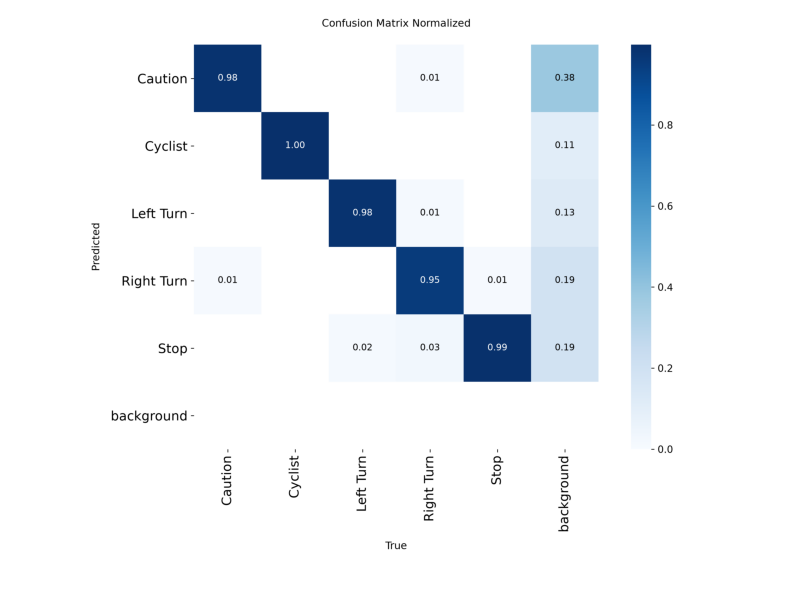

In [ ]:
%matplotlib inline
from PIL import Image

img=Image.open(os.path.join(run_dir, 'confusion_matrix_normalized.png'))
plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

##Prediction

In [ ]:
model = YOLO(best_pt)  # load a custom model

# Predict with the model with any image from internet?
img = 'https://raw.githubusercontent.com/zhengyangsu/Computer-Vision-Project-Overview/main/misc/A-cyclist-riding.jpg'
results = model(img, save=True, project=project_dir)
predict_dir = str(results[0].save_dir)   # predict, predict2, ... (Ultralytics numbers it)
print(predict_dir)


image 1/1 G:\My Drive\Colab_Notebooks\workbench\A-cyclist-riding.jpg: 640x640 1 Cyclist, 82.8ms
Speed: 4.5ms preprocess, 82.8ms inference, 3.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to G:\My Drive\Colab_Notebooks\workbench\predict
G:\My Drive\Colab_Notebooks\workbench\predict


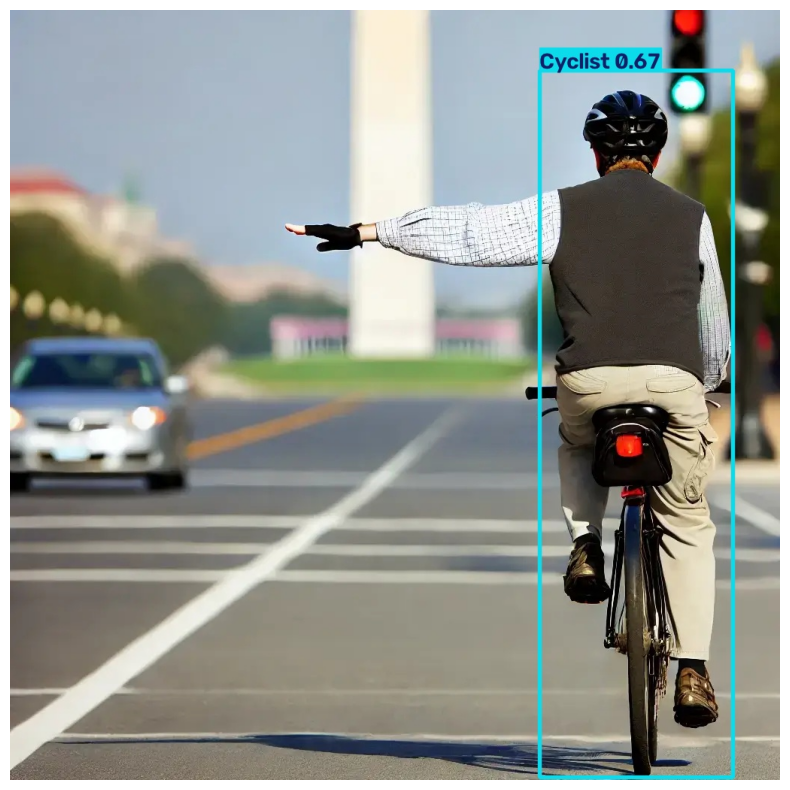

In [ ]:
# SHOW THE IMAGE STORED
%matplotlib inline
from PIL import Image

img=Image.open(os.path.join(predict_dir, 'A-cyclist-riding.jpg'))
plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

# **Training curves**

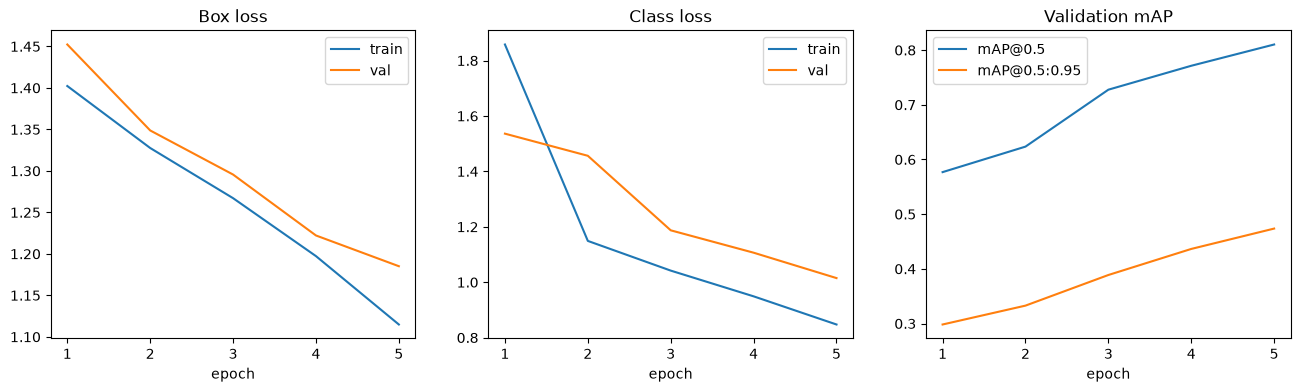

In [ ]:
#If the validation loss flattens or rises while the training loss keeps falling, the model is overfitting.
#If mAP is still climbing at the last epoch, train longer.
res = pd.read_csv(os.path.join(run_dir, 'results.csv'))
res.columns = res.columns.str.strip()           # column names can have stray spaces

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(res['epoch'], res['train/box_loss'], label='train')
ax[0].plot(res['epoch'], res['val/box_loss'], label='val')
ax[0].set_title('Box loss')

ax[1].plot(res['epoch'], res['train/cls_loss'], label='train')
ax[1].plot(res['epoch'], res['val/cls_loss'], label='val')
ax[1].set_title('Class loss')

ax[2].plot(res['epoch'], res['metrics/mAP50(B)'], label='mAP@0.5')
ax[2].plot(res['epoch'], res['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
ax[2].set_title('Validation mAP')

for a in ax:
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# **Learning curve by training**

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\My Drive\Colab_Notebooks\config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=lc_10, nbs=64, nms=None

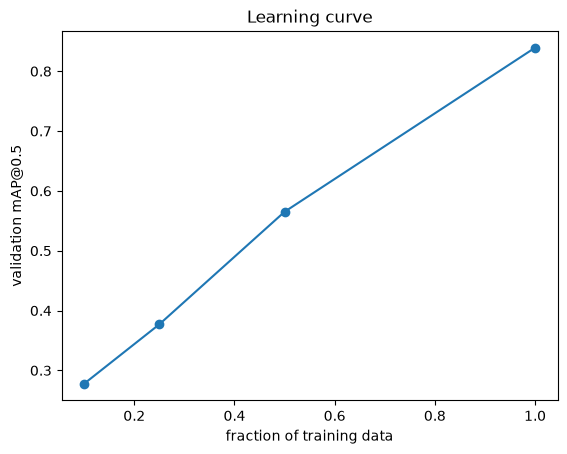

In [ ]:
#If the curve is still rising at 1.0, more data would improve the model.
#If it flattens, more data of the same kind won’t help much. You would need more variety instead.

fractions = [0.1, 0.25, 0.5, 1.0]
scores = []

for frac in fractions:
    m = YOLO('yolov8n.pt')                       # fresh model every time
    m.train(data=config_path, epochs=10, imgsz=640, batch=16,
            fraction=frac, fliplr=0.0, seed=0,
            project=project_dir, name=f'lc_{int(frac*100)}', exist_ok=True)
    val = m.val(data=config_path, split="val")  # score on the same validation set
    scores.append(val.box.map50)
    print(f'fraction {frac}: mAP50 = {val.box.map50:.3f}')

plt.plot(fractions, scores, marker='o')
plt.xlabel('fraction of training data')
plt.ylabel('validation mAP@0.5')
plt.title('Learning curve')
plt.show()


# Tune Test

In [ ]:
model = YOLO('yolov8s.pt')        # fresh pretrained model for the search


#default settings model.train(data=config_path, epochs=5, patience=5, batch=8,lr0=0.0005, workers=2, project=project_dir)

model.tune(
    data=config_path,
    epochs=10,                    # short trials
    iterations=10,                # number of trials
    fraction=0.3,                 # each trial uses 30% of the training images
    batch=16, imgsz=640,
    optimizer='AdamW',            # fixed, so lr0 takes effect
    lrf=0.01,                     # fixed
    warmup_epochs=1,              # fixed
    fliplr=0.0,                   # fixed, no left/right flipping
    space={'lr0': (1e-4, 5e-3), 'lrf': (0.01, 0.1), 'scale': (0.3, 0.7)},
    plots=False, save=False,
    project=os.path.join(base_dir, 'experiments'),
)


Tuner: Initialized Tuner instance with 'tune_dir=G:\My Drive\Colab_Notebooks\experiments\tune-2'
Tuner:  Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/10 with hyperparameters: {'lr0': 0.002, 'lrf': 0.01, 'scale': 0.5}

MultiTrainer 1/1: fine-tuning on G:\My Drive\Colab_Notebooks\config.yaml
MultiTrainer results saved to G:\My Drive\Colab_Notebooks\experiments\multitrain-4\multitrain_results.json
Saved G:\My Drive\Colab_Notebooks\experiments\tune-2\tune_scatter_plots.png
Saved G:\My Drive\Colab_Notebooks\experiments\tune-2\tune_fitness.png

Tuner: 1/10 iterations complete  (375.26s)
Tuner: Results saved to G:\My Drive\Colab_Notebooks\experiments\tune-2
Tuner: Best fitness=0.25925 observed at iteration 1
Tuner: Best fitness metrics are {'metrics/precision(B)': 0.71757, 'metrics/recall(B)': 0.40293, 'metrics/mAP50(B)': 0.4263, 'metrics/mAP50-95(B)': 0.25925, 'val/box_loss': 1.8362, 'val/cls_loss': 3.028, 'val/dfl_loss': 1.84065

# Read the best hyperparameter values

In [ ]:
import glob, yaml

exp_dir = os.path.join(base_dir, 'experiments')
tune_dir = max(glob.glob(os.path.join(exp_dir, 'tune*')), key=os.path.getmtime)
with open(os.path.join(tune_dir, 'best_hyperparameters.yaml')) as f:
    best = yaml.safe_load(f)

print('Tune folder:', tune_dir)
print('lr0 =', best['lr0'], '| scale =', best['scale'])

Tune folder: G:\My Drive\Colab_Notebooks\experiments\tune-2
lr0 = 0.00131 | scale = 0.5


# Re Train

In [ ]:
model = YOLO('yolov8s.pt')

model.train(
    data=config_path, epochs=30, batch=16, imgsz=640,
    optimizer='AdamW', lr0=best['lr0'], lrf=0.01,
    scale=best['scale'], warmup_epochs=1, fliplr=0.0,
    project=project_dir,
)

run_dir = str(model.trainer.save_dir)
best_pt = os.path.join(run_dir, 'weights', 'best.pt')
print('This run', run_dir)

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\My Drive\Colab_Notebooks\config.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00131, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nm

Ultralytics 8.4.192  Python-3.14.8 torch-2.15.0.dev20261004+cu132 CUDA:0 (NVIDIA GeForce RTX 2080 Ti, 11264MiB)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
WARNING val: Slow image access detected (ping: 1.2±0.3 ms, read: 18.1±4.0 MB/s, size: 50.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning G:\My Drive\Colab_Notebooks\Cycling_Hand_Signals_Dataset\Final_data\labels\test.cache... 768 images, 145 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 768/768 214.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 1.4it/s 35.0s
                   all        768       1148      0.783      0.818       0.86      0.516
               Caution        234        247      0.629      0.542      0.673      0.388
               Cyclist        384        569      0.956      0.956      0.982      

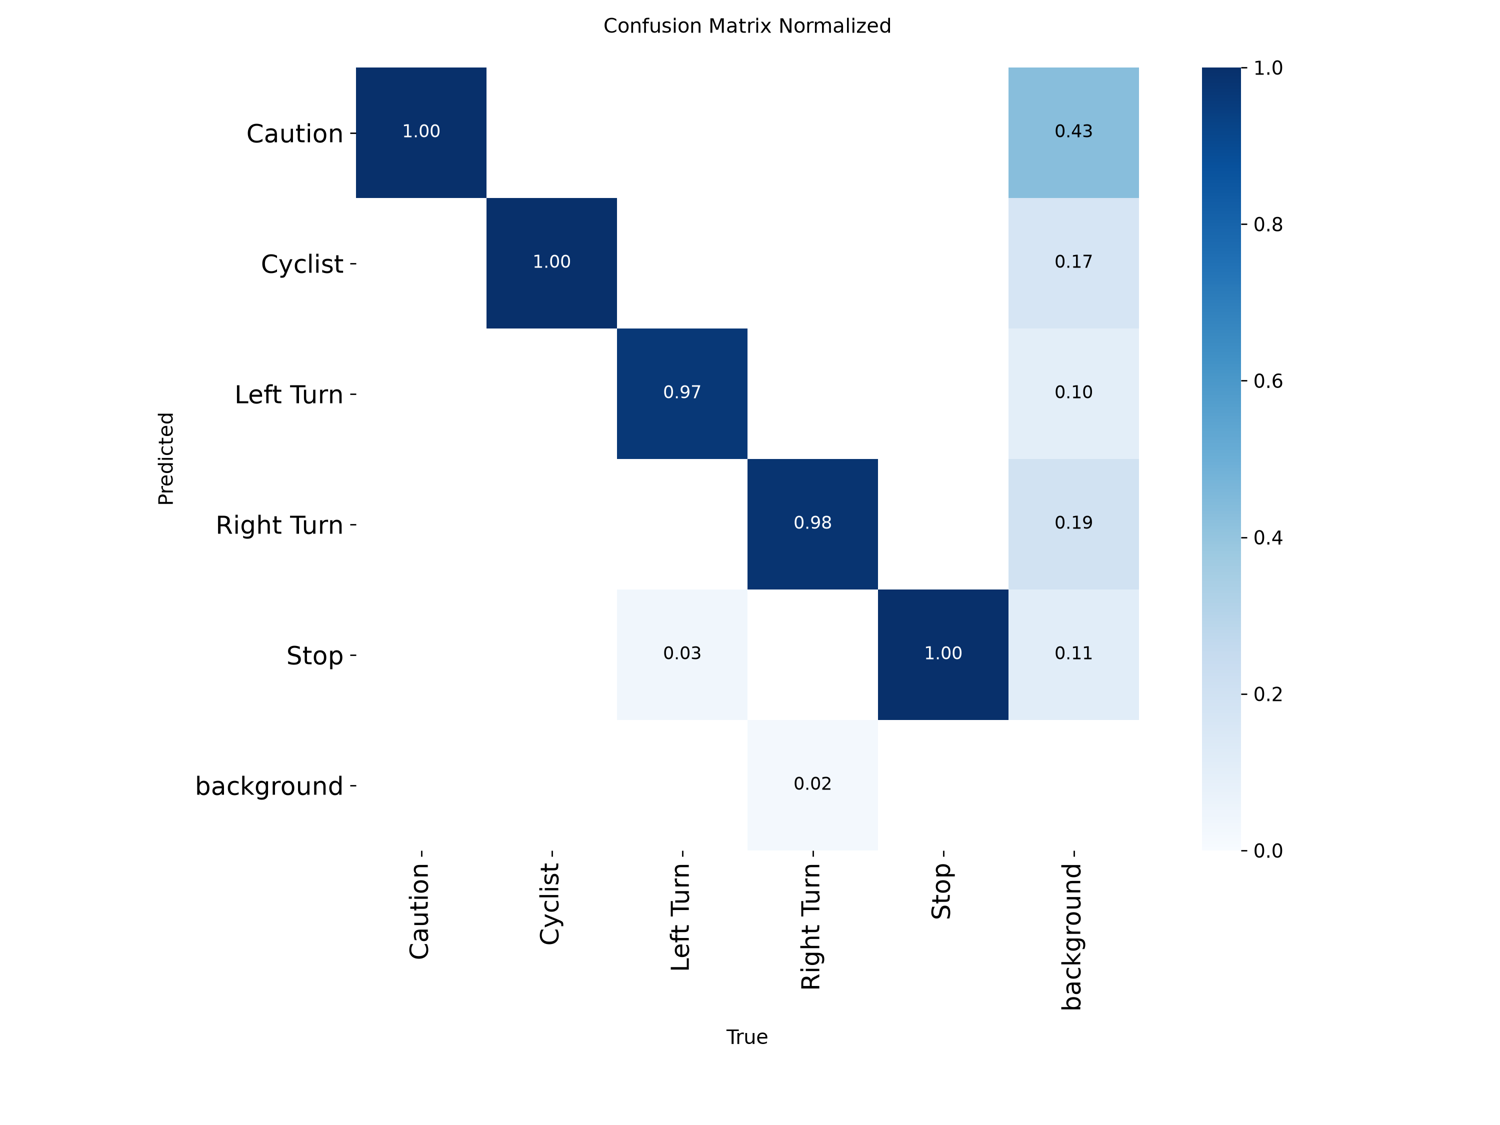

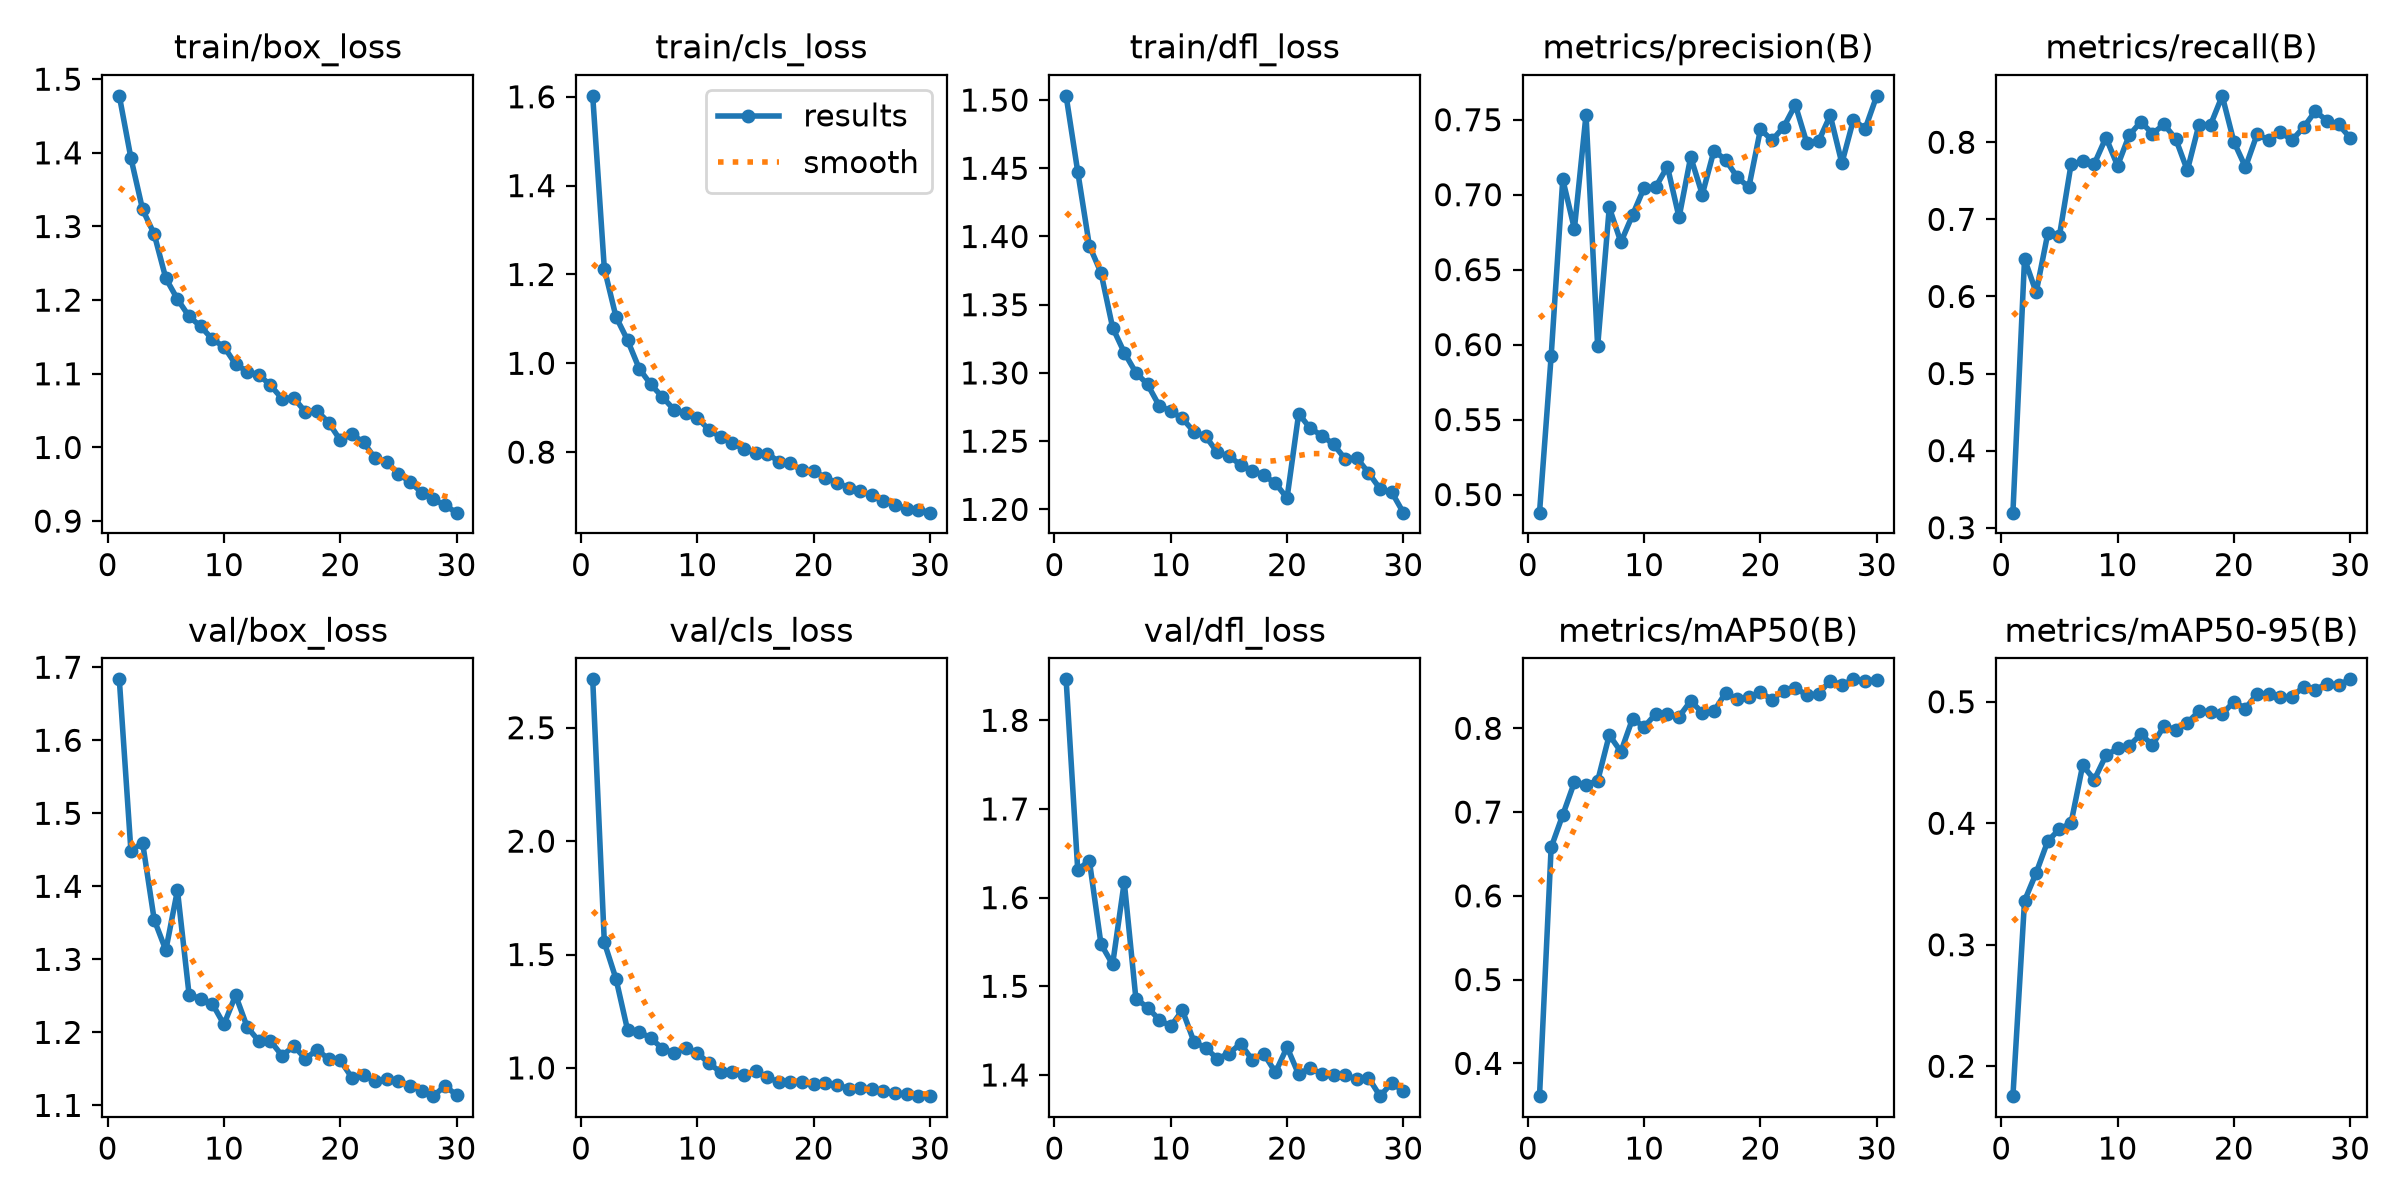

In [ ]:
# ---- scores of best.pt on the test split ----
model = YOLO(best_pt)
metrics = model.val(data=config_path, split='test', project=project_dir) #default was validation split

print('mAP50-95:', metrics.box.map)
print('mAP50   :', metrics.box.map50)
print('P       :', metrics.box.mp)
print('R       :', metrics.box.mr)
print('mAP50-95 per class:', dict(zip(class_names, metrics.box.maps)), '\n\n')

# ---- which epoch was best ----
res = pd.read_csv(os.path.join(run_dir, 'results.csv'))
res.columns = res.columns.str.strip()
best_row = res.loc[res['metrics/mAP50-95(B)'].idxmax()]
print('Best epoch:', int(best_row['epoch']), '| mAP50-95:', best_row['metrics/mAP50-95(B)'], '\n\n')

# ---- confusion matrix and training curves ----
val_dir = str(metrics.save_dir)     # the folder model.val created
img = Image.open(os.path.join(val_dir, 'confusion_matrix_normalized.png'))
display(img.resize((img.width // 2, img.height // 2)))
display(Image.open(os.path.join(run_dir, 'results.png')))
